In [23]:
import pandas as pd 
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from tabulate import tabulate
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np


In [24]:
open_source_model_results_path = "/Users/mariyajose/Documents/Sarcasm_Final/Prompt_Sensitivity/outputs.csv"
gemini_result_path = "/Users/mariyajose/Documents/Sarcasm_Final/Prompt_Sensitivity/gemini.csv"
chatgpt_resukts_path = "/Users/mariyajose/Documents/Sarcasm_Final/Prompt_Sensitivity/chatgpt.csv"

In [25]:
data_one = pd.read_csv(open_source_model_results_path)
data_one.head()

,label,comment,author,subreddit,score,ups,downs,date,created_utc,parent_comment,llama_temp0,llama_temp1,ds_temp0,ds_temp1
0,0,They would also have to accept as valid blocks...,mmeijeri,Bitcoin,6,-1,-1,2016-11,2016-11-01 22:00:23,"BU only follows ""Nakamoto consensus"" by block ...",1,1,1,1.0
1,0,Or less.,damndammit,Bitcoin,1,1,0,2016-09,2016-09-02 15:19:41,Please don't use Exchanges for long-term stora...,1,1,1,0.0
2,0,"thx rusty (and all other devs), great work.",Lite_Coin_Guy,Bitcoin,5,-1,-1,2016-10,2016-10-08 12:09:32,ELI5: MimbleWimble,1,1,1,0.0
3,0,"he is promoting ethereum lol, something tells ...",linktype,Bitcoin,4,-1,-1,2016-11,2016-11-14 02:47:16,"Andreas M. Antonopoulos talks about Bitcoin, f...",1,1,1,0.0
4,0,LOL... That's way to risky,Light_of_Lucifer,Bitcoin,1,1,0,2016-09,2016-09-11 07:42:42,If you are brave/crazy you can open a Bitfinex...,1,1,1,1.0


In [26]:
data_two = pd.read_csv(gemini_result_path)
data_two.head()

,comment,parent_comment,author,gemini_label
0,They would also have to accept as valid blocks...,"BU only follows ""Nakamoto consensus"" by block ...",mmeijeri,0
1,Or less.,Please don't use Exchanges for long-term stora...,damndammit,0
2,"thx rusty (and all other devs), great work.",ELI5: MimbleWimble,Lite_Coin_Guy,0
3,"he is promoting ethereum lol, something tells ...","Andreas M. Antonopoulos talks about Bitcoin, f...",linktype,1
4,LOL... That's way to risky,If you are brave/crazy you can open a Bitfinex...,Light_of_Lucifer,1


In [27]:
# 1. Check if author and _parent_comment match row-by-row
authors_match = (data_one['author'].values == data_two['author'].values).all()
comments_match = (data_one['parent_comment'].values == data_two['parent_comment'].values).all()

if authors_match and comments_match:
    # 2. Get the name and values of the last column from df2
    last_col_name = data_two.columns[-1]
    
    # 3. Add it to the end of df1
    data_one[last_col_name] = data_two.iloc[:, -1].values
    print(f"Success! Column '{last_col_name}' was added to df1.")
else:
    print("Error: The rows in df1 and df2 do not match based on author and _parent_comment.")

Success! Column 'gemini_label' was added to df1.


In [28]:
data_three = pd.read_csv(chatgpt_resukts_path)
data_three.head()

,comment,parent_comment,author,chatgpt_label
0,They would also have to accept as valid blocks...,"BU only follows ""Nakamoto consensus"" by block ...",mmeijeri,0
1,Or less.,Please don't use Exchanges for long-term stora...,damndammit,0
2,"thx rusty (and all other devs), great work.",ELI5: MimbleWimble,Lite_Coin_Guy,0
3,"he is promoting ethereum lol, something tells ...","Andreas M. Antonopoulos talks about Bitcoin, f...",linktype,0
4,LOL... That's way to risky,If you are brave/crazy you can open a Bitfinex...,Light_of_Lucifer,0


In [29]:
# 1. Check if author and _parent_comment match row-by-row
authors_match = (data_one['author'].values == data_three['author'].values).all()
comments_match = (data_one['parent_comment'].values == data_three['parent_comment'].values).all()

if authors_match and comments_match:
    # 2. Get the name and values of the last column from df2
    last_col_name = data_three.columns[-1]
    
    # 3. Add it to the end of df1
    data_one[last_col_name] = data_three.iloc[:, -1].values
    print(f"Success! Column '{last_col_name}' was added to df1.")
else:
    print("Error: The rows in df1 and df2 do not match based on author and _parent_comment.")

Success! Column 'chatgpt_label' was added to df1.


In [30]:
data_one.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 906 entries, 0 to 905
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   label           906 non-null    int64  
 1   comment         906 non-null    object 
 2   author          906 non-null    object 
 3   subreddit       906 non-null    object 
 4   score           906 non-null    int64  
 5   ups             906 non-null    int64  
 6   downs           906 non-null    int64  
 7   date            906 non-null    object 
 8   created_utc     906 non-null    object 
 9   parent_comment  906 non-null    object 
 10  llama_temp0     906 non-null    int64  
 11  llama_temp1     906 non-null    int64  
 12  ds_temp0        906 non-null    int64  
 13  ds_temp1        905 non-null    float64
 14  gemini_label    906 non-null    int64  
 15  chatgpt_label   906 non-null    int64  
dtypes: float64(1), int64(9), object(6)
memory usage: 113.4+ KB


In [31]:
rows_to_drop = data_one[data_one['ds_temp1'].isna()].index

print(f"Row index(es) with missing values: {list(rows_to_drop)}")

Row index(es) with missing values: [683]


In [32]:
data_one = data_one.dropna(subset=['ds_temp1'])
data_one['ds_temp1'] = data_one['ds_temp1'].astype('int64')

In [33]:
# Save the combined results to csv file 
data_one.to_csv("/Users/mariyajose/Documents/Sarcasm_Final/Prompt_Sensitivity/prompt_sensitivity.csv",index = False)

In [34]:
# List of the model prediction column names
result_columns = [
    'llama_temp0', 
    'llama_temp1',  
    'ds_temp0', 
    'ds_temp1',
    'gemini_label',
    'chatgpt_label'
]

# Human labelled column
actual_label = data_one['label']

# Collect performance metrics for each model
results = []

for model_name in result_columns:
    predicted_label = data_one[model_name]
    
    # Calculate performance accuracy
    accuracy = accuracy_score(actual_label, predicted_label)
    
    # Evaluation metrics
    precision = precision_score(actual_label, predicted_label, average='macro', zero_division=0)
    recall = recall_score(actual_label, predicted_label, average='macro', zero_division=0)
    F1_score = f1_score(actual_label, predicted_label, average='macro', zero_division=0)
    

    results.append([
        model_name,
        f"{accuracy:.4f}",
        f"{precision:.4f}",
        f"{recall:.4f}",
        f"{F1_score:.4f}",
    ])

# Table headers
headers = [
    "Model", 
    "Accuracy", 
    "Precision", 
    "Recall", 
    "F1-Score", 
]

# Print formatted table using tabulate
print(tabulate(results, headers=headers, tablefmt="grid"))

+---------------+------------+-------------+----------+------------+
| Model         |   Accuracy |   Precision |   Recall |   F1-Score |
+===============+============+=============+==========+============+
| llama_temp0   |     0.5503 |      0.5161 |   0.5018 |     0.3803 |
+---------------+------------+-------------+----------+------------+
| llama_temp1   |     0.5691 |      0.5712 |   0.5303 |     0.4702 |
+---------------+------------+-------------+----------+------------+
| ds_temp0      |     0.5989 |      0.5926 |   0.5807 |     0.5751 |
+---------------+------------+-------------+----------+------------+
| ds_temp1      |     0.5923 |      0.5877 |   0.5685 |     0.555  |
+---------------+------------+-------------+----------+------------+
| gemini_label  |     0.5249 |      0.5173 |   0.517  |     0.5168 |
+---------------+------------+-------------+----------+------------+
| chatgpt_label |     0.8077 |      0.8166 |   0.8165 |     0.8077 |
+---------------+------------+----

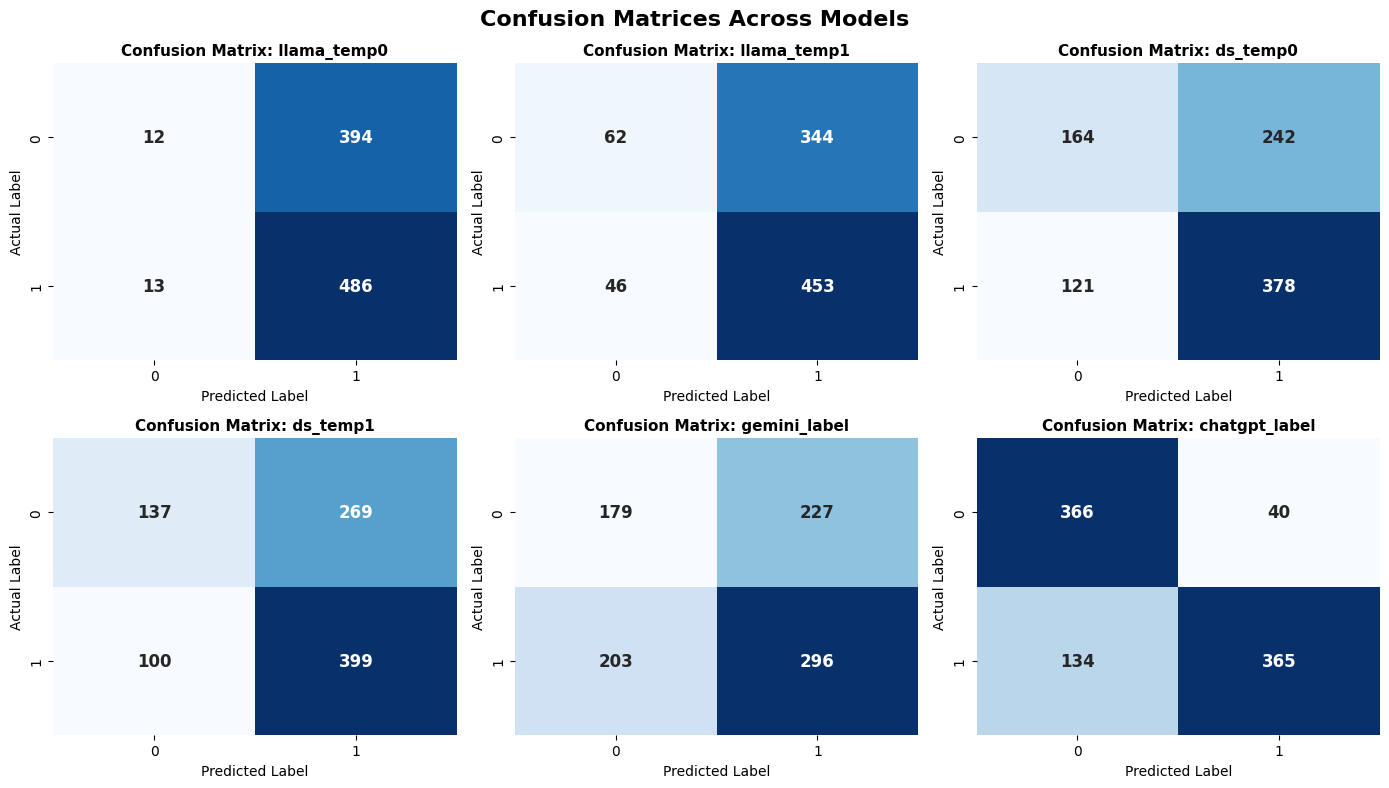

In [35]:
# Model columns to evaluate
result_columns = [
    "llama_temp0",
    "llama_temp1",
    "ds_temp0",
    "ds_temp1",
    "gemini_label",
    "chatgpt_label"
]

# Create a 2x3 subplot grid
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

# Generate Confusion Matrix heatmap for each model
for idx, model in enumerate(result_columns):
    ConfusionMatrix = confusion_matrix(data_one["label"], data_one[model])

    sns.heatmap(
        ConfusionMatrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[idx],
        cbar=False,
        annot_kws={"size": 12, "weight": "bold"},
    )

    axes[idx].set_title(
        f"Confusion Matrix: {model}", fontsize=11, fontweight="bold"
    )
    axes[idx].set_xlabel("Predicted Label", fontsize=10)
    axes[idx].set_ylabel("Actual Label", fontsize=10)

plt.suptitle("Confusion Matrices Across Models", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

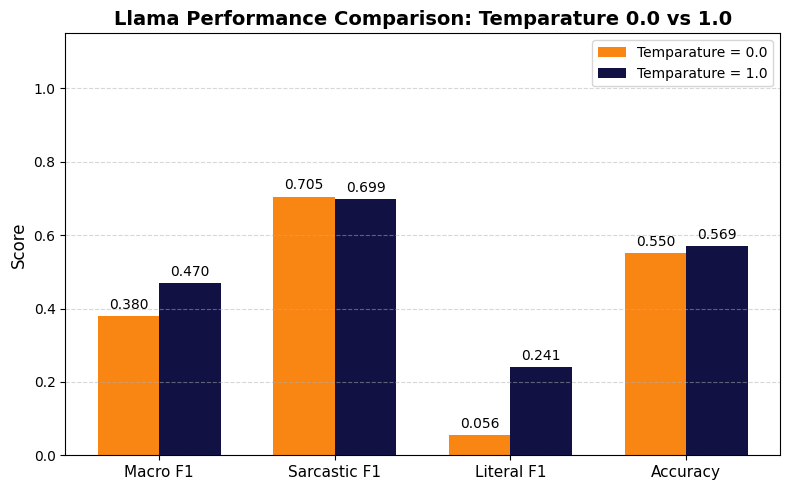

In [36]:
human_labelled_column = 'label'  
sarcastic_label = 1      
literal_label = 0          

actual_label = data_one[human_labelled_column]
predicted_label_temp0 = data_one['llama_temp0']
predicted_label_temp1 = data_one['llama_temp1']

# Compute metrics for both temperatures
def get_metrics(true_label, predicted_label):
    return [
        f1_score(true_label, predicted_label, average='macro'),
        f1_score(true_label, predicted_label, pos_label=sarcastic_label, average='binary'),
        f1_score(true_label, predicted_label, pos_label=literal_label, average='binary'),
        accuracy_score(true_label, predicted_label)
    ]

metrics = ['Macro F1', 'Sarcastic F1', 'Literal F1', 'Accuracy']
t0_scores = get_metrics(actual_label, predicted_label_temp0)
t1_scores = get_metrics(actual_label, predicted_label_temp1)

# Plot grouped bar chart
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
bar1 = ax.bar(x - width/2, t0_scores, width, label='Temparature = 0.0', color='#F98513')
bar2 = ax.bar(x + width/2, t1_scores, width, label='Temparature = 1.0', color='#111144')

ax.set_ylabel('Score', fontsize=12)
ax.set_title('Llama Performance Comparison: Temparature 0.0 vs 1.0', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim(0, 1.15)
ax.legend(loc='upper right')
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Add value labels on top of bars
ax.bar_label(bar1, padding=3, fmt='%.3f')
ax.bar_label(bar2, padding=3, fmt='%.3f')

plt.tight_layout()
plt.show()

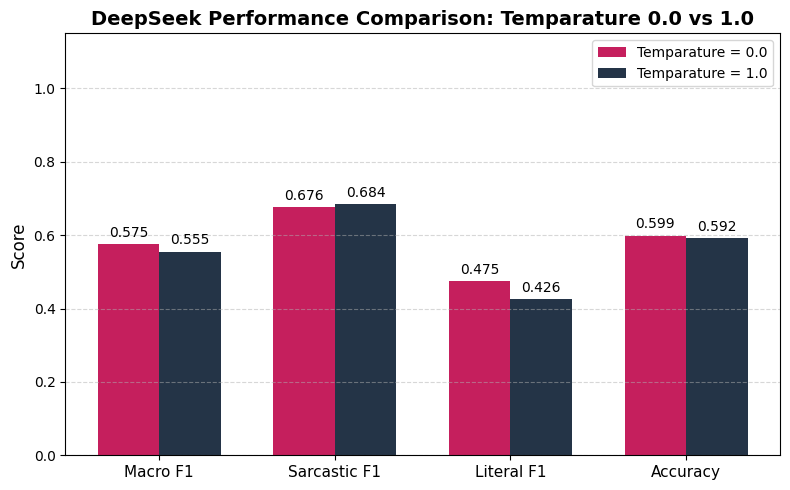

In [37]:
human_labelled_column = 'label'  
sarcastic_label = 1      
literal_label = 0         

actual_label = data_one[human_labelled_column]
predicted_label_temp0 = data_one['ds_temp0']
predicted_label_temp1 = data_one['ds_temp1']

# Compute metrics for both temperatures
def get_metrics(true_label, predicted_label):
    return [
        f1_score(true_label, predicted_label, average='macro'),
        f1_score(true_label, predicted_label, pos_label=sarcastic_label, average='binary'),
        f1_score(true_label, predicted_label, pos_label=literal_label, average='binary'),
        accuracy_score(true_label, predicted_label)
    ]

metrics = ['Macro F1', 'Sarcastic F1', 'Literal F1', 'Accuracy']
t0_scores = get_metrics(actual_label, predicted_label_temp0)
t1_scores = get_metrics(actual_label, predicted_label_temp1)

# Plot grouped bar chart
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
bar1 = ax.bar(x - width/2, t0_scores, width, label='Temparature = 0.0', color='#C51F5D')
bar2 = ax.bar(x + width/2, t1_scores, width, label='Temparature = 1.0', color='#243447')

ax.set_ylabel('Score', fontsize=12)
ax.set_title('DeepSeek Performance Comparison: Temparature 0.0 vs 1.0', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim(0, 1.15)
ax.legend(loc='upper right')
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Add value labels on top of bars
ax.bar_label(bar1, padding=3, fmt='%.3f')
ax.bar_label(bar2, padding=3, fmt='%.3f')

plt.tight_layout()
plt.show()

In [38]:
import numpy as np
import pandas as pd
from sklearn.metrics import cohen_kappa_score
from statsmodels.stats.contingency_tables import mcnemar
from tabulate import tabulate



In [39]:
first_labeled_df = pd.read_csv("/Users/mariyajose/Documents/Sarcasm_Final/Data_Labelling/data_labeling.csv")
# first_labeled_df = first_labeled_df.drop(683)


In [40]:
first_labeled_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 906 entries, 0 to 905
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   label           906 non-null    int64 
 1   comment         906 non-null    object
 2   author          906 non-null    object
 3   subreddit       906 non-null    object
 4   score           906 non-null    int64 
 5   ups             906 non-null    int64 
 6   downs           906 non-null    int64 
 7   date            906 non-null    object
 8   created_utc     906 non-null    object
 9   parent_comment  906 non-null    object
 10  llama_temp0     906 non-null    int64 
 11  llama_temp1     906 non-null    int64 
 12  chatgpt         906 non-null    int64 
 13  gemini          906 non-null    int64 
 14  ds_temp0        906 non-null    int64 
 15  ds_temp1        906 non-null    int64 
 16  gemini_label    906 non-null    int64 
 17  chatgpt_label   906 non-null    int64 
dtypes: int64(1

In [41]:
second_labeled_df = pd.read_csv("/Users/mariyajose/Documents/Sarcasm_Final/Prompt_Sensitivity/prompt_sensitivity.csv")

second_labeled_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 905 entries, 0 to 904
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   label           905 non-null    int64 
 1   comment         905 non-null    object
 2   author          905 non-null    object
 3   subreddit       905 non-null    object
 4   score           905 non-null    int64 
 5   ups             905 non-null    int64 
 6   downs           905 non-null    int64 
 7   date            905 non-null    object
 8   created_utc     905 non-null    object
 9   parent_comment  905 non-null    object
 10  llama_temp0     905 non-null    int64 
 11  llama_temp1     905 non-null    int64 
 12  ds_temp0        905 non-null    int64 
 13  ds_temp1        905 non-null    int64 
 14  gemini_label    905 non-null    int64 
 15  chatgpt_label   905 non-null    int64 
dtypes: int64(10), object(6)
memory usage: 113.2+ KB


In [42]:
# Find the row(s) in df1 whose 'comment' is not present in df2
extra_rows = first_labeled_df[~first_labeled_df['comment'].isin(second_labeled_df['comment'])]

print("Extra row(s) found in dataset 1:")
print(extra_rows)

# Remove the extra row(s) from df1 to match df2's rows based on the comment column
first_labeled_df = first_labeled_df[first_labeled_df['comment'].isin(second_labeled_df['comment'])].reset_index(drop=True)

# Optional: save the cleaned dataset back to a file
# first_labeled_df.to_csv('dataset1_cleaned.csv', index=False)

Extra row(s) found in dataset 1:
     label                                            comment      author  \
683      0  I would argue for once every 3 hours, but I su...  Gappleto97   

    subreddit  score  ups  downs     date          created_utc  \
683   Bitcoin      1    1      0  2014-07  2014-07-13 06:19:13   

                                        parent_comment  llama_temp0  \
683  Not millions per block yet, but it can process...            1   

     llama_temp1  chatgpt  gemini  ds_temp0  ds_temp1  gemini_label  \
683            1        0       0         1         1             0   

     chatgpt_label  
683              0  


In [43]:
# Models to compare
model_cols = ["llama_temp0", "llama_temp1", "ds_temp0", "ds_temp1","gemini_label","chatgpt_label"]

In [44]:



def interpret_kappa(k):
    if k < 0:
        return "Poor"
    elif k <= 0.20:
        return "Slight"
    elif k <= 0.40:
        return "Fair"
    elif k <= 0.60:
        return "Moderate"
    elif k <= 0.80:
        return "Substantial"
    else:
        return "Almost Perfect"


# Tabular Repeatability Analysis
results = []

for model in model_cols:
    r1 = first_labeled_df[model]
    r2 = second_labeled_df[model]

    total = len(r1)
    matches = (r1 == r2).sum()
    flips = total - matches
    consistency_pct = (matches / total) * 100

    # Directional flips
    flip_0_to_1 = ((r1 == 0) & (r2 == 1)).sum()
    flip_1_to_0 = ((r1 == 1) & (r2 == 0)).sum()

    # Cohen's Kappa
    kappa = cohen_kappa_score(r1, r2)
    kappa_interp = interpret_kappa(kappa)

    # McNemar's Test for systematic shift
    contingency_table = pd.crosstab(r1, r2)

    if contingency_table.shape == (2, 2):
        mcnemar_p = mcnemar(contingency_table.values, exact=True).pvalue
        shift_bias = (
            "No Bias Shift" if mcnemar_p >= 0.05 else "Systematic Shift"
        )
    else:
        mcnemar_p = np.nan
        shift_bias = "N/A"

    results.append(
        [
            model,
            f"{matches}/{total}",
            f"{consistency_pct:.2f}%",
            flips,
            f"{flip_0_to_1} (0→1) | {flip_1_to_0} (1→0)",
            f"{kappa:.4f}",
            kappa_interp,
            f"{mcnemar_p:.4f}" if not np.isnan(mcnemar_p) else "N/A",
            shift_bias,
        ]
    )

headers = [
    "Model Name",
    "Matches",
    "Consistency (%)",
    "Total Flips",
    "Flip Breakdown (R1→R2)",
    "Cohen's Kappa",
    "Reliability",
    "McNemar p-val",
    "Bias Shift Check",
]

print("=== RUN 1 vs. RUN 2 REPEATABILITY SUMMARY ===")
print(tabulate(results, headers=headers, tablefmt="grid"))

=== RUN 1 vs. RUN 2 REPEATABILITY SUMMARY ===
+---------------+-----------+-------------------+---------------+--------------------------+-----------------+----------------+-----------------+--------------------+
| Model Name    | Matches   | Consistency (%)   |   Total Flips | Flip Breakdown (R1→R2)   |   Cohen's Kappa | Reliability    |   McNemar p-val | Bias Shift Check   |
+===============+===========+===================+===============+==========================+=================+================+=================+====================+
| llama_temp0   | 769/905   | 84.97%            |           136 | 116 (0→1) | 20 (1→0)     |          0.0238 | Slight         |          0      | Systematic Shift   |
+---------------+-----------+-------------------+---------------+--------------------------+-----------------+----------------+-----------------+--------------------+
| llama_temp1   | 650/905   | 71.82%            |           255 | 174 (0→1) | 81 (1→0)     |          0.0231 | Slight  